In [2]:
import pandas as pd
df = pd.read_csv("data/superstore_sales.csv")

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:
print(df.shape)
df.info()

(10800, 21)
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quant

In [5]:
# the rows where values of order date are nulls
bad = df[df["Order Date"].isnull()]
print(len(bad))
bad.head(10)

806


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


As we can see, the original data is a merge of three different tables:

**Table	- Columns**

Orders - Row ID, Order ID, Order Date, ... Profit (21 columns)

People - Person, Region

Returns -	Returned, Order ID

So, in order not to lose any information, we will move them into their own tables, then remove them from the orders.

In [6]:
# save the people and returns tables
people = df.loc[9995:9998, ["Row ID", "Order ID"]].copy()
people.columns = ["Person", "Region"]

returns = df.loc[10000:, ["Row ID", "Order ID"]].copy()
returns.columns = ["Returned", "Order ID"]
returns = returns.drop_duplicates() # to have one row for each return

# Keep only real orders in the main table
df = df[df["Order Date"].notnull()].copy()

# Now Row ID can safely become a number
df["Row ID"] = df["Row ID"].astype(int)

In [7]:
# Saving already clean seperate tables in the drive
people.to_csv("data/people.csv", index=False)
returns.to_csv("data/returns.csv", index=False)
df.to_csv("data/superstore_clean.csv", index=False)

In [8]:
df[df["Postal Code"].isnull()][["City", "State"]].drop_duplicates()
# with this we can see that we have postal codes null for Burlington, Vermont

,City,State
2234,Burlington,Vermont


In [9]:
mask = (df["City"] == "Burlington") & (df["State"] == "Vermont")
df[mask]["Postal Code"].value_counts(dropna=False)
# the output shows that no Vermont Burlington row has a postal code anywhere in
# the data, so we will them fill from outside knowledge

Postal Code
NaN    11
Name: count, dtype: int64

In [10]:
# we look up that the postal code is 05401, so we fill them in
mask = (df["City"] == "Burlington") & (df["State"] == "Vermont") & (df["Postal Code"].isnull())
df.loc[mask, "Postal Code"] = 5401

In [11]:
#check that everything worked well
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

print(df["Postal Code"].isnull().sum())   # expect 0
print(df[(df["City"] == "Burlington") & (df["State"] == "Vermont")]["Postal Code"].unique())   # expect ['05401']

0
<StringArray>
['05401']
Length: 1, dtype: str


In [12]:
df[["Order Date", "Ship Date"]].dtypes
#both show object which means pandas sees them as plain text
# It can’t sort, subtract, or group text by month, so we need real dates

Order Date    str
Ship Date     str
dtype: object

In [13]:
# convert to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

In [14]:
#verifing it worked
print(df[["Order Date", "Ship Date"]].dtypes)
print(df["Order Date"].min(), "->", df["Order Date"].max())
print("Shipped before ordered:", (df["Ship Date"] < df["Order Date"]).sum())

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object
2015-01-03 00:00:00 -> 2018-12-30 00:00:00
Shipped before ordered: 0


In [15]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")

In [16]:
df[["Order Date", "Year", "Month", "Year-Month"]].head()

,Order Date,Year,Month,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


In [17]:
#should be 48
df["Year-Month"].nunique()

48

In [18]:
df["Year"].value_counts().sort_index() # some stats

Year
2015    1993
2016    2102
2017    2587
2018    3312
Name: count, dtype: int64

In [19]:
#save progress
df.to_csv("superstore_clean.csv", index=False)

Now I will group by Product Category, Region, and Customer Segment to compute aggregate Sales & Profit


In [20]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat

,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


In [21]:
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
reg

,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


In [22]:
seg = df.groupby("Segment")[["Sales", "Profit"]].sum()
seg

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


Totals can be misleading, so let's add some more useful metrics

In [23]:
def summarize(by):
    out = df.groupby(by).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Avg_Discount=("Discount", "mean"),
    )
    out["Profit_Margin_%"] = (out["Profit"] / out["Sales"] * 100).round(2)
    return out.round(2).sort_values("Sales", ascending=False)

summarize("Category")

,Sales,Profit,Orders,Avg_Discount,Profit_Margin_%
Category,,,,,
Technology,836154.03,145454.95,1544,0.13,17.40
Furniture,741999.80,18451.27,1764,0.17,2.49
Office Supplies,719047.03,122490.80,3742,0.16,17.04


In [24]:
summarize("Region")

,Sales,Profit,Orders,Avg_Discount,Profit_Margin_%
Region,,,,,
West,725457.82,108418.45,1611,0.11,14.94
East,678781.24,91522.78,1401,0.15,13.48
Central,501239.89,39706.36,1175,0.24,7.92
South,391721.90,46749.43,822,0.15,11.93


In [25]:
summarize("Segment")

,Sales,Profit,Orders,Avg_Discount,Profit_Margin_%
Segment,,,,,
Consumer,1161401.34,134119.21,2586,0.16,11.55
Corporate,706146.37,91979.13,1514,0.16,13.03
Home Office,429653.15,60298.68,909,0.15,14.03


In [26]:
df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum").round(0)

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0,8880.0,33697.0
East,3046.0,41015.0,47462.0
South,6771.0,19986.0,19992.0
West,11505.0,52610.0,44304.0


In [27]:
print(df["Sales"].sum().round(2), summarize("Category")["Sales"].sum().round(2))
print(df["Profit"].sum().round(2), summarize("Region")["Profit"].sum().round(2))

2297200.86 2297200.86
286397.02 286397.02


In [28]:
# let's test if Central Furniture is discounted especially heavily
df.groupby(["Region", "Category"])["Discount"].mean().unstack().round(2)

Category,Furniture,Office Supplies,Technology
Region,,,
Central,0.30,0.25,0.13
East,0.15,0.14,0.14
South,0.12,0.17,0.11
West,0.13,0.09,0.13


as we can see central furniture has the highest avarage discount in the whole grid(30%) and it is the only loss-making combination(from the pivot table)

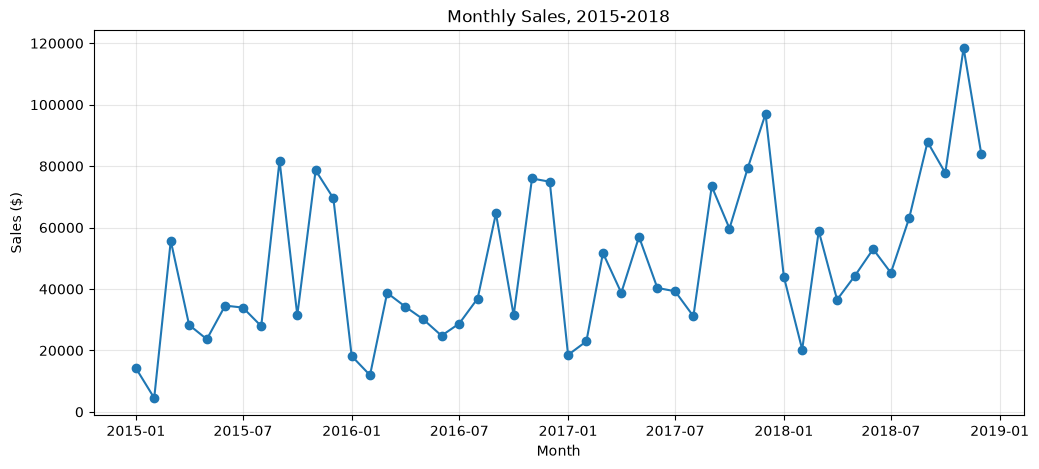

In [29]:
#plotting the data
#monthly sales velocity
import matplotlib.pyplot as plt
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()   # periods -> dates, so matplotlib can plot them

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales, 2015-2018")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.grid(alpha=0.3)
plt.show()

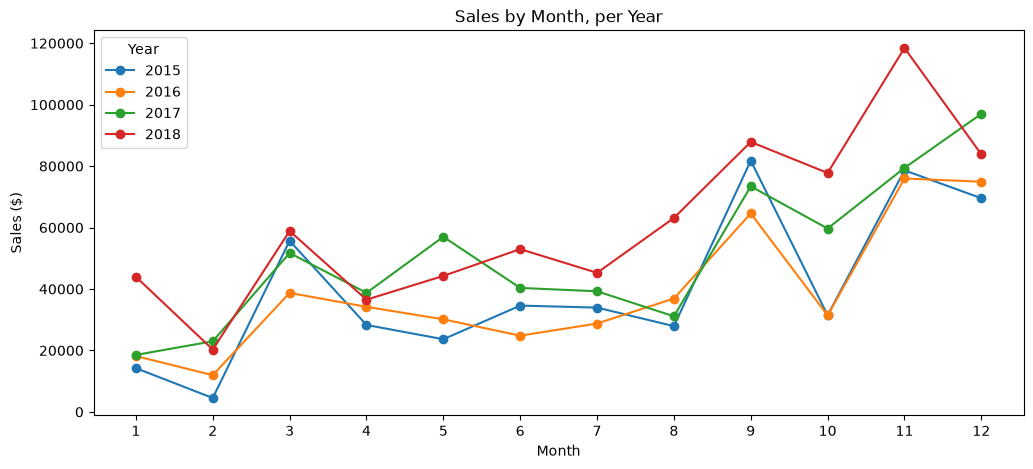

In [30]:
#seasonality
season = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
season.plot(figsize=(12, 5), marker="o")
plt.title("Sales by Month, per Year")
plt.xticks(range(1, 13))
plt.ylabel("Sales ($)")
plt.show()

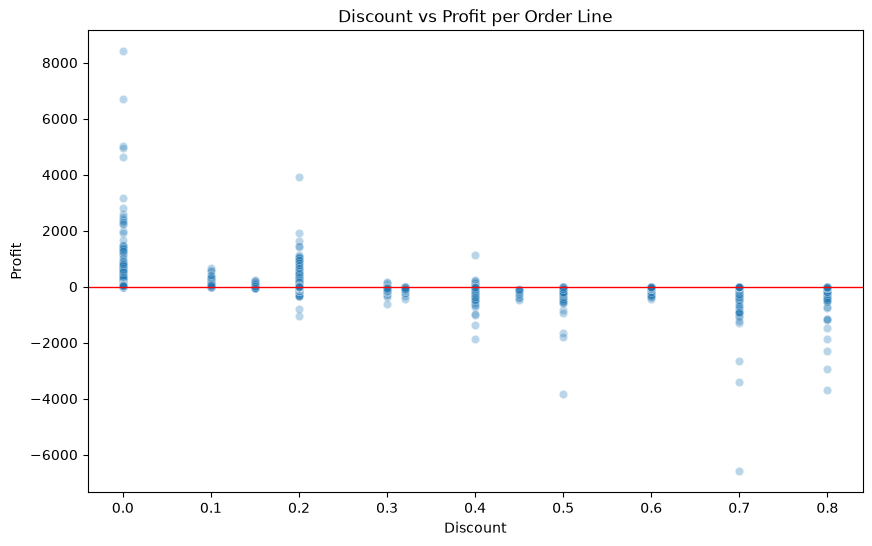

In [31]:
#discount vs profit
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3)
plt.axhline(0, color="red", linewidth=1)
plt.title("Discount vs Profit per Order Line")
plt.show()

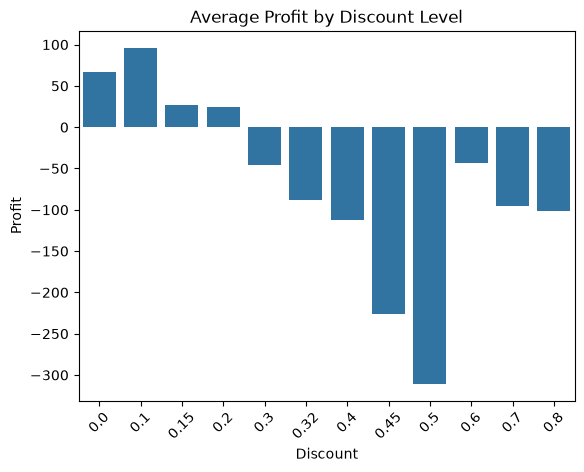

In [32]:
#average profit at each discount level (clearer than the scatter)
sns.barplot(data=df, x="Discount", y="Profit", estimator="mean", errorbar=None)
plt.xticks(rotation=45)
plt.title("Average Profit by Discount Level")
plt.show()

In [33]:
#let's do one more check before conclusions, group discounts into bands,
#so the patters is easier to state, and we can see the total money involved
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 0.8],
    labels=["None", "Low (up to 20%)", "Medium (21-40%)", "High (over 40%)"],
)

df.groupby("Discount Band", observed=True).agg(
    Lines=("Profit", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean"),
).round(2)

,Lines,Total_Sales,Total_Profit,Avg_Profit
Discount Band,,,,
None,4798,1087908.47,320987.60,66.90
Low (up to 20%),3803,846522.24,100785.47,26.50
Medium (21-40%),460,234137.90,-35817.47,-77.86
High (over 40%),933,128632.25,-99558.59,-106.71


# **Business Outcomes**

**1. Discounts above 20% are significantly reducing profitability.**

Although discounts above 20% account for only 14% of all sales records, they generate approximately $135K in losses, wiping out nearly a third of the profit earned from the remaining sales. I would recommend setting a discount limit of around 20%, with additional approval required for higher discounts.

**2. Furniture generates high revenue but relatively little profit.**

Furniture accounts for 32% of total sales ($742K), yet contributes only 6% of total profit. Its profit margin is just 2.5%, compared to approximately 17% for Technology and Office Supplies. This suggests that Furniture pricing and discount policies need to be reviewed before focusing on increasing its sales volume.

**3. Heavy discounting is contributing to lower profitability in the Central region.**

The Central region has a profit margin of 7.9%, almost half of the West's 14.9%. It also offers the highest average discounts (24%), reaching 30% for Furniture. Notably, Central Furniture is the only region-category combination operating at a loss, with a negative profit of $2,871. Reviewing discount practices in this region could help improve its overall profitability.

**4. Sales follow a clear seasonal pattern, with overall growth over time.**

Sales follow a fairly consistent pattern each year: January and February are typically slower months, followed by a rise in March and a significant increase from September through December. November 2018 was the strongest month, with approximately $118K in sales. Overall, 2018 also outperformed previous years in nearly every month. These trends can help the business plan inventory, staffing, and promotional activities more effectively throughout the year.

**5. West and Technology are the strongest contributors to profit.**

The West region generates the highest profit (\$108K), with a margin of 14.9%. Technology is the most profitable product category, generating \$145K in profit at a 17.4% margin on \$836K in sales. These are the strongest-performing areas and could be good priorities for future growth investments.

**6. Customer segments have a relatively small impact on profitability.**

Profit margins across customer segments range from 11.6% for Consumer to 14.0% for Home Office, a difference of only 2.4 percentage points. This is considerably smaller than the differences between product categories, where margins vary by approximately 15 percentage points. This suggests that profitability is influenced more by what the business sells and how it prices its products than by who it sells to. I would therefore prioritize product mix and discount policies over targeting specific customer segments to improve profits.

In [34]:
orders = pd.read_csv("data/superstore_clean.csv")

g = orders.groupby("Product ID").agg(
    names=("Product Name", "nunique"),
    cats=("Category", "nunique"),
    subs=("Sub-Category", "nunique"),
)
g[(g["names"] > 1) | (g["cats"] > 1) | (g["subs"] > 1)]

,names,cats,subs
Product ID,,,
FUR-BO-10002213,2,1,1
FUR-CH-10001146,2,1,1
FUR-FU-10001473,2,1,1
FUR-FU-10004017,2,1,1
FUR-FU-10004091,2,1,1
FUR-FU-10004270,2,1,1
FUR-FU-10004848,2,1,1
FUR-FU-10004864,2,1,1
OFF-AP-10000576,2,1,1
